# Module 10, Part 2: Quantization, post-training and quantization-aware

This notebook is the runnable companion to Part 2 of the Module 10 learning content. Quantization stores weights (and sometimes activations) as small integers with a scale, instead of 32-bit floats. We build it from scratch so every step is visible, then test it.

1. **How rounding error grows as bits fall**, for one scale per tensor against one scale per output channel.
2. **Genuine integer inference**: int8 weights and activations, int32 accumulation, and a check that it agrees with the simulated version.
3. **Post-training quantization (PTQ) against quantization-aware training (QAT)** at 8, 6, 4, 3 and 2 bits.
4. **An outlier channel**: how a single large row ruins per-tensor quantization, and what per-channel scales fix.
5. **What you save**: model size at each bit width.

**Setting.** The same digits data and 64-512-512-10 network as Part 1. Three seeds for each experiment.

In [1]:
import copy, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
torch.set_num_threads(1)
INK, BODY, MUTED = "#14161B", "#4E5563", "#7C838C"
NAVY, GREEN, AMBER, KEY, RULE = "#1C3D6E", "#0E6B57", "#8A6A18", "#7A2E8A", "#D9DCE2"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": RULE, "axes.labelcolor": BODY, "xtick.color": BODY, "ytick.color": BODY,
    "axes.grid": True, "grid.color": RULE, "font.size": 10,
})

In [2]:
import numpy as np
import torch
from sklearn.datasets import load_digits


def load_digits_split(seed=0, test_fraction=0.2):
    """Return (X_train, y_train, X_test, y_test). Pixels are scaled to [0, 1] and flattened to 64 values."""
    d = load_digits()
    X = (d.data / 16.0).astype(np.float32)
    y = d.target.astype(np.int64)
    rng = np.random.RandomState(seed)
    idx = rng.permutation(len(X))
    n_test = int(len(X) * test_fraction)
    te, tr = idx[:n_test], idx[n_test:]
    return torch.tensor(X[tr]), torch.tensor(y[tr]), torch.tensor(X[te]), torch.tensor(y[te])

In [3]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


def mlp(sizes):
    layers = []
    for i in range(len(sizes) - 2):
        layers += [nn.Linear(sizes[i], sizes[i + 1]), nn.ReLU()]
    layers += [nn.Linear(sizes[-2], sizes[-1])]
    return nn.Sequential(*layers)


def accuracy(model, X, y):
    model.eval()
    with torch.no_grad():
        return (model(X).argmax(1) == y).float().mean().item()


def distill_loss(student_logits, teacher_logits, y, T=4.0, alpha=0.7):
    """alpha * T^2 * KL(teacher_T || student_T) + (1 - alpha) * cross entropy with the hard label."""
    soft = F.kl_div(F.log_softmax(student_logits / T, 1), F.softmax(teacher_logits / T, 1), reduction="batchmean") * T * T
    return alpha * soft + (1 - alpha) * F.cross_entropy(student_logits, y)


def train(model, X, y, epochs=60, lr=3e-3, batch=64, seed=0, teacher=None, T=4.0, alpha=0.7, masks=None, wd=0.0):
    """Train with cross entropy, or with the distillation loss when a teacher is given.
    `masks` (a list matching the Linear layers) are re-applied after every step so pruned weights stay zero."""
    g = torch.Generator().manual_seed(seed)
    opt = torch.optim.Adam(model.parameters(), lr=lr, weight_decay=wd)
    if teacher is not None:
        teacher.eval()
        with torch.no_grad():
            tl = teacher(X)
    lin = [m for m in model if isinstance(m, nn.Linear)]
    n = len(X)
    for ep in range(epochs):
        model.train()
        perm = torch.randperm(n, generator=g)
        for i in range(0, n, batch):
            b = perm[i:i + batch]
            out = model(X[b])
            loss = distill_loss(out, tl[b], y[b], T, alpha) if teacher is not None else F.cross_entropy(out, y[b])
            opt.zero_grad(); loss.backward(); opt.step()
            if masks is not None:
                with torch.no_grad():
                    for m, mk in zip(lin, masks): m.weight.mul_(mk)
    return model


def count_params(model):
    return sum(p.numel() for p in model.parameters())


def count_nonzero(model):
    return sum((p != 0).sum().item() for p in model.parameters())


def magnitude_masks(model, sparsity, scope="global"):
    """Masks that zero the smallest-magnitude weights. Biases are never pruned."""
    lin = [m for m in model if isinstance(m, nn.Linear)]
    if scope == "global":
        allw = torch.cat([m.weight.detach().abs().flatten() for m in lin])
        k = int(sparsity * allw.numel())
        thr = allw.kthvalue(k).values if k > 0 else allw.min() - 1
        return [(m.weight.detach().abs() > thr).float() for m in lin]
    masks = []
    for m in lin:
        w = m.weight.detach().abs().flatten(); k = int(sparsity * w.numel())
        thr = w.kthvalue(k).values if k > 0 else w.min() - 1
        masks.append((m.weight.detach().abs() > thr).float())
    return masks


def apply_masks(model, masks):
    lin = [m for m in model if isinstance(m, nn.Linear)]
    with torch.no_grad():
        for m, mk in zip(lin, masks): m.weight.mul_(mk)


def structured_prune(model, keep):
    """Remove whole hidden neurons (rows of one layer and the matching columns of the next) with the
    smallest L2 norm of incoming weights. Returns a smaller, still dense, network."""
    lin = [m for m in model if isinstance(m, nn.Linear)]
    keep_idx = []
    for m in lin[:-1]:
        k = max(1, int(round(keep * m.out_features)))
        keep_idx.append(m.weight.detach().norm(dim=1).topk(k).indices.sort().values)
    sizes = [lin[0].in_features] + [len(i) for i in keep_idx] + [lin[-1].out_features]
    new = mlp(sizes)
    nl = [m for m in new if isinstance(m, nn.Linear)]
    prev = torch.arange(lin[0].in_features)
    for j, (m, n_) in enumerate(zip(lin, nl)):
        rows = keep_idx[j] if j < len(keep_idx) else torch.arange(m.out_features)
        with torch.no_grad():
            n_.weight.copy_(m.weight[rows][:, prev]); n_.bias.copy_(m.bias[rows])
        prev = rows
    return new


# ---------------------------------------------------------------- experiments used by notebook 1 and the learning content
def timeit(fn, repeats=200, warmup=20):
    """Median wall-clock seconds of fn() over `repeats` calls, after a warm-up."""
    import time
    for _ in range(warmup): fn()
    ts = []
    for _ in range(repeats):
        t0 = time.perf_counter(); fn(); ts.append(time.perf_counter() - t0)
    return float(np.median(ts))

In [4]:
import copy
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F


def qparams(x, bits=8, per_channel=False, symmetric=True, clip=None):
    """Scale (and zero point) that map the range of x onto signed integers of `bits` bits.
    per_channel=True gives one scale per output row (dim 0). `clip` limits the range to a percentile of |x|."""
    qmax = 2 ** (bits - 1) - 1
    a = x.abs()
    if per_channel:
        m = a.flatten(1).max(1).values if clip is None else torch.quantile(a.flatten(1), clip, dim=1)
        scale = (m / qmax).clamp_min(1e-12).view(-1, *([1] * (x.dim() - 1)))
    else:
        m = a.max() if clip is None else torch.quantile(a.flatten(), clip)
        scale = (m / qmax).clamp_min(1e-12)
    return scale, qmax


def quantize(x, scale, qmax):
    return torch.clamp(torch.round(x / scale), -qmax - 1, qmax)


def fake_quant(x, bits=8, per_channel=False, clip=None):
    scale, qmax = qparams(x.detach(), bits, per_channel, clip=clip)
    return quantize(x, scale, qmax) * scale


class FakeQuantSTE(torch.autograd.Function):
    """Round in the forward pass, pass the gradient straight through in the backward pass."""
    @staticmethod
    def forward(ctx, x, scale, qmax):
        return torch.clamp(torch.round(x / scale), -qmax - 1, qmax) * scale

    @staticmethod
    def backward(ctx, g):
        return g, None, None


def ste_quant(x, bits, per_channel=False):
    scale, qmax = qparams(x.detach(), bits, per_channel)
    return FakeQuantSTE.apply(x, scale, qmax)


def quantize_weights(model, bits=8, per_channel=True):
    """Return a copy of a Sequential MLP whose Linear weights are rounded to `bits` bits (weight-only, simulated)."""
    m = copy.deepcopy(model)
    with torch.no_grad():
        for l in m:
            if isinstance(l, nn.Linear):
                l.weight.copy_(fake_quant(l.weight, bits, per_channel))
    return m


def weight_error(w, bits, per_channel):
    q = fake_quant(w, bits, per_channel)
    return ((q - w).pow(2).mean().sqrt() / w.pow(2).mean().sqrt()).item()


def int8_inference(model, X, calib, per_channel=True, act_clip=None):
    """Genuine integer arithmetic: int8 weights and int8 activations, int32 accumulation, float rescale between layers.
    Activation scales come from the calibration set. Returns the float logits."""
    lin = [l for l in model if isinstance(l, nn.Linear)]
    with torch.no_grad():
        # calibrate the input to every Linear layer
        acts, h = [], calib
        for i, l in enumerate(lin):
            acts.append(h); h = l(h)
            if i < len(lin) - 1: h = torch.relu(h)
        h = X
        for i, l in enumerate(lin):
            sw, qm = qparams(l.weight, 8, per_channel)
            wq = quantize(l.weight, sw, qm).to(torch.int8).numpy()
            sa, _ = qparams(acts[i], 8, False, clip=act_clip)
            aq = quantize(h, sa, 127).to(torch.int8).numpy()
            acc = aq.astype(np.int32) @ wq.astype(np.int32).T                        # integer matmul, int32 accumulator
            sw_row = sw.view(1, -1).numpy() if per_channel else float(sw)
            h = torch.from_numpy(acc.astype(np.float32) * (float(sa) * sw_row)) + l.bias
            if i < len(lin) - 1: h = torch.relu(h)
    return h


def model_bytes(model, bits=32, scales=False):
    """Storage for the weights at `bits` bits per weight (biases stay 32-bit), plus 4 bytes per output row if per-channel scales."""
    b = 0
    for l in model:
        if isinstance(l, nn.Linear):
            b += l.weight.numel() * bits / 8 + l.bias.numel() * 4 + (l.out_features * 4 if scales else 0)
    return int(b)


class QATLinear(nn.Module):
    def __init__(self, lin, bits):
        super().__init__(); self.lin, self.bits = lin, bits

    def forward(self, x):
        return F.linear(x, ste_quant(self.lin.weight, self.bits, True), self.lin.bias)


def qat_model(model, bits):
    layers = []
    for l in model:
        layers.append(QATLinear(copy.deepcopy(l), bits) if isinstance(l, nn.Linear) else copy.deepcopy(l))
    return nn.Sequential(*layers)


def freeze_qat(qm, bits):
    """Collapse a QAT model back into an ordinary MLP holding the rounded weights."""
    layers = []
    for l in qm:
        if isinstance(l, QATLinear):
            n = nn.Linear(l.lin.in_features, l.lin.out_features)
            with torch.no_grad():
                n.weight.copy_(fake_quant(l.lin.weight, bits, True)); n.bias.copy_(l.lin.bias)
            layers.append(n)
        else: layers.append(l)
    return nn.Sequential(*layers)


def train_qat(model, X, y, bits, epochs=20, lr=1e-3, seed=0):
    qm = qat_model(model, bits)
    train(qm, X, y, epochs=epochs, lr=lr, seed=seed)
    return freeze_qat(qm, bits)


def add_outlier_channel(model, layer=0, channel=3, factor=30.0):
    """A function-preserving change: scale one hidden neuron's incoming weights and bias by `factor` and its outgoing
    weights by 1/factor. The float network is unchanged, but its weight range is now dominated by one row."""
    m = copy.deepcopy(model)
    lin = [l for l in m if isinstance(l, nn.Linear)]
    with torch.no_grad():
        lin[layer].weight[channel] *= factor; lin[layer].bias[channel] *= factor
        lin[layer + 1].weight[:, channel] /= factor
    return m


# ---------------------------------------------------------------- experiments
def exp_bits(X, y, Xte, yte, bits_list=(8, 6, 4, 3, 2), seeds=range(3), qat_epochs=20):
    out = {b: {"ptq_tensor": [], "ptq_channel": [], "qat": []} for b in bits_list}
    out["float"] = []
    for seed in seeds:
        torch.manual_seed(seed)
        base = train(mlp([64, 512, 512, 10]), X, y, epochs=60, seed=seed)
        out["float"].append(accuracy(base, Xte, yte))
        for b in bits_list:
            out[b]["ptq_tensor"].append(accuracy(quantize_weights(base, b, False), Xte, yte))
            out[b]["ptq_channel"].append(accuracy(quantize_weights(base, b, True), Xte, yte))
            out[b]["qat"].append(accuracy(train_qat(base, X, y, b, epochs=qat_epochs, seed=seed), Xte, yte))
    return out


def exp_outlier(X, y, Xte, yte, seeds=range(3), factor=30.0):
    out = {"float": [], "tensor8": [], "channel8": [], "tensor6": [], "channel6": [], "err_tensor": [], "err_channel": []}
    for seed in seeds:
        torch.manual_seed(seed)
        base = train(mlp([64, 512, 512, 10]), X, y, epochs=60, seed=seed)
        m = add_outlier_channel(base, 0, 3, factor)
        out["float"].append(accuracy(m, Xte, yte))
        for b in (8, 6):
            out[f"tensor{b}"].append(accuracy(quantize_weights(m, b, False), Xte, yte))
            out[f"channel{b}"].append(accuracy(quantize_weights(m, b, True), Xte, yte))
        w = [l for l in m if isinstance(l, nn.Linear)][0].weight.detach()
        out["err_tensor"].append(weight_error(w, 6, False)); out["err_channel"].append(weight_error(w, 6, True))
    return out

In [5]:
Xtr, ytr, Xte, yte = load_digits_split(0)
base = train(mlp([64, 512, 512, 10]), Xtr, ytr, epochs=60, seed=0)
print("float32 test accuracy:", round(accuracy(base, Xte, yte), 3))
w1 = base[0].weight.detach()
print("first-layer weights: min %.3f  max %.3f  mean |w| %.3f" % (w1.min(), w1.max(), w1.abs().mean()))

float32 test accuracy: 0.986
first-layer weights: min -0.346  max 0.446  mean |w| 0.078


## 1. How big is the rounding error?

For a weight tensor $w$ and $b$ bits, the integer grid has $2^{b-1}-1$ positive steps, and the step size (the scale) is set by the largest magnitude. The *relative error* below is the root mean square rounding error divided by the root mean square of the weights, for the first layer.

bits   per-tensor relative error   per-channel relative error
   8                      0.0108                       0.0052
   6                      0.0440                       0.0210
   4                      0.1957                       0.0938
   3                      0.4620                       0.2190
   2                      0.9897                       0.6783


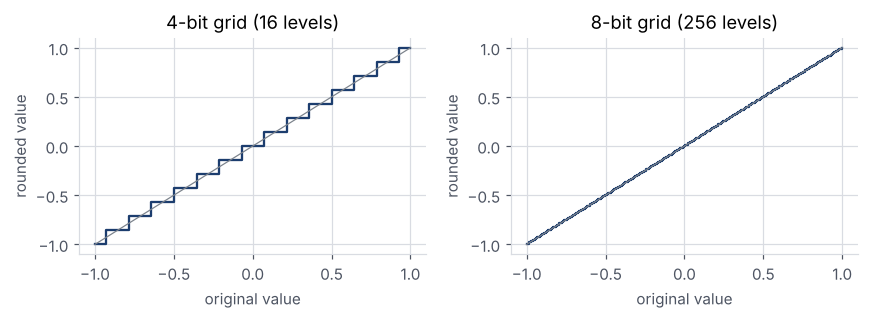

In [6]:
print("bits   per-tensor relative error   per-channel relative error")
for b in (8, 6, 4, 3, 2):
    print(f"{b:4d} {weight_error(w1, b, False):27.4f} {weight_error(w1, b, True):28.4f}")
x = np.linspace(-1, 1, 400); fig, ax = plt.subplots(1, 2, figsize=(8, 3))
for a, b in zip(ax, (4, 8)):
    t = torch.tensor(x, dtype=torch.float32); a.plot(x, fake_quant(t, b).numpy(), color=NAVY, drawstyle="steps-mid"); a.plot(x, x, color=MUTED, lw=0.8)
    a.set_title(f"{b}-bit grid ({2 ** b} levels)"); a.set_xlabel("original value"); a.set_ylabel("rounded value")
plt.tight_layout(); plt.show()

Each bit removed roughly doubles the error. The staircase picture shows why: the fewer the levels, the wider the steps, and every weight is moved to the nearest step. Per-channel scales already cut the error to roughly a third or a quarter of the per-tensor error, because each row of the layer gets a grid fitted to its own range; Section 4 shows how much more that matters when one row is unusual.

## 2. Real integer arithmetic

Weight-only rounding (what `quantize_weights` does) keeps the arithmetic in floating point and only reduces storage. For the speed and energy savings of integer hardware, the *activations* must be integers too. `int8_inference` quantizes the weights and the activations to 8 bits, multiplies in integers with a 32-bit accumulator, then rescales to floats between layers. The activation scales come from a **calibration set** of 256 training images.

In [7]:
calib = Xtr[:256]
with torch.no_grad():
    f = base(Xte); q = int8_inference(base, Xte, calib)
    wq = quantize_weights(base, 8, True)(Xte)
print("float32 accuracy      :", round((f.argmax(1) == yte).float().mean().item(), 4))
print("weight-only int8      :", round((wq.argmax(1) == yte).float().mean().item(), 4))
print("full int8 (int32 acc.):", round((q.argmax(1) == yte).float().mean().item(), 4))
print("predictions that differ from float32, full int8:", int((q.argmax(1) != f.argmax(1)).sum()), "of", len(yte))
print("largest logit difference from float32:", round((q - f).abs().max().item(), 4))
for clip in (None, 0.999, 0.99):
    q2 = int8_inference(base, Xte, calib, act_clip=clip)
    print(f"activation range from {'the maximum' if clip is None else f'the {clip:g} quantile'}: accuracy {(q2.argmax(1) == yte).float().mean().item():.4f}")

float32 accuracy      : 0.9861
weight-only int8      : 0.9861
full int8 (int32 acc.): 0.9861
predictions that differ from float32, full int8: 0 of 359
largest logit difference from float32: 0.7645
activation range from the maximum: accuracy 0.9861
activation range from the 0.999 quantile: accuracy 0.9861
activation range from the 0.99 quantile: accuracy 0.9861


Eight-bit integer inference reproduces the float network almost exactly on this task: not one of the 359 predictions changes, and the largest logit difference is small. The calibration choice makes no difference on this small network, but it is worth knowing about: clipping the activation range at a high percentile trades a few saturated values for a finer grid for everything else. On larger networks with heavy-tailed activations this choice matters much more.

## 3. Post-training quantization against quantization-aware training

PTQ rounds the trained weights and stops. QAT keeps the rounded weights in the forward pass during 20 more epochs of training, using the straight-through estimator: the forward pass rounds, the backward pass pretends rounding was the identity so the gradient can reach the real-valued weights that sit underneath. We test both, with one scale per tensor and per channel.

float32 baseline: 0.983
bits   PTQ per-tensor   PTQ per-channel   QAT (per-channel)
   8            0.983             0.983               0.985
   6            0.983             0.983               0.983
   4            0.945             0.983               0.982
   3            0.219             0.941               0.984
   2            0.086             0.368               0.982
(45 s)


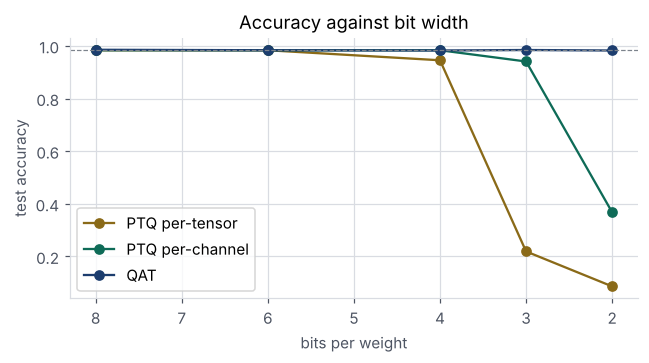

In [8]:
t0 = time.time()
B = exp_bits(Xtr, ytr, Xte, yte)
print(f"float32 baseline: {np.mean(B['float']):.3f}")
print("bits   PTQ per-tensor   PTQ per-channel   QAT (per-channel)")
for b in (8, 6, 4, 3, 2):
    print(f"{b:4d} {np.mean(B[b]['ptq_tensor']):16.3f} {np.mean(B[b]['ptq_channel']):17.3f} {np.mean(B[b]['qat']):19.3f}")
print(f"({time.time() - t0:.0f} s)")
bits = [8, 6, 4, 3, 2]
fig, ax = plt.subplots(figsize=(6, 3.4))
for key, lab, c in (("ptq_tensor", "PTQ per-tensor", AMBER), ("ptq_channel", "PTQ per-channel", GREEN), ("qat", "QAT", NAVY)):
    ax.plot(bits, [np.mean(B[b][key]) for b in bits], marker="o", color=c, label=lab)
ax.axhline(np.mean(B["float"]), color=MUTED, lw=0.8, ls="--"); ax.invert_xaxis(); ax.set_xlabel("bits per weight"); ax.set_ylabel("test accuracy"); ax.legend(); ax.set_title("Accuracy against bit width")
plt.tight_layout(); plt.show()

Down to 6 bits, plain rounding is enough with either kind of scale. With one scale per tensor, 4 bits already costs about four points and 3 bits destroys the model (0.219). With per-channel scales, 4 bits is still free and 3 bits costs about four points, and at 2 bits it collapses to 0.368. QAT is far more robust: it holds 0.982 even at 2 bits, because the network learns to place its weights where a three-level grid can hold them. Treat that last number with care: this network is hugely over-parameterized for the digits, so it has the capacity to survive almost anything, and a tighter network or a harder task would not be so forgiving. The practical summary: 8 bits is nearly free and is the default, per-channel scales buy about a bit and a half, and QAT is what you reach for when you go below 4.

## 4. One outlier channel

Per-tensor quantization sets the scale from the largest weight in the whole tensor. If one row is much larger than the rest, every other row is squeezed into a few levels. We construct this on purpose with a change that provably leaves the float network unchanged: multiply one hidden neuron's incoming weights by 30 and divide its outgoing weights by 30.

In [9]:
O = exp_outlier(Xtr, ytr, Xte, yte)
print("float32 accuracy, with the outlier channel        :", round(np.mean(O["float"]), 3), "(same function as before)")
print("8 bits per-tensor / per-channel                   :", round(np.mean(O["tensor8"]), 3), "/", round(np.mean(O["channel8"]), 3))
print("6 bits per-tensor / per-channel                   :", round(np.mean(O["tensor6"]), 3), "/", round(np.mean(O["channel6"]), 3))
print("first-layer relative error at 6 bits, tensor / channel:", round(np.mean(O["err_tensor"]), 3), "/", round(np.mean(O["err_channel"]), 3))

float32 accuracy, with the outlier channel        : 0.983 (same function as before)
8 bits per-tensor / per-channel                   : 0.983 / 0.983
6 bits per-tensor / per-channel                   : 0.974 / 0.983
first-layer relative error at 6 bits, tensor / channel: 0.366 / 0.021


The float network is untouched, yet per-tensor quantization now hurts at 6 bits (0.974 against 0.983) while per-channel quantization is unaffected, and the underlying weight error shows the real size of the effect: 0.366 against 0.021. Accuracy is a blunt instrument here; the error is already large, and on a harder task it would show up in the score. Each row has its own scale, so the outlier row only spoils itself. Real language and vision models have outlier channels of this kind naturally, which is why per-channel weight scales are the standard and why activation outliers are the main obstacle for quantizing large models to 8 bits and below.

## 5. What you actually save

In [10]:
print(f"{'format':34s} {'bytes':>9s} {'ratio to float32':>17s}")
f32 = model_bytes(base, 32)
for name, bts in (("float32", f32), ("int8 + per-channel scales", model_bytes(base, 8, True)), ("int6 (packed) + scales", model_bytes(base, 6, True)),
                  ("int4 (packed) + scales", model_bytes(base, 4, True)), ("int2 (packed) + scales", model_bytes(base, 2, True))):
    print(f"{name:34s} {bts:9d} {f32 / bts:17.2f}")

format                                 bytes  ratio to float32
float32                              1204264              1.00
int8 + per-channel scales             308304              3.91
int6 (packed) + scales                233296              5.16
int4 (packed) + scales                158288              7.61
int2 (packed) + scales                 83280             14.46


The ratio is a little under 32/bits because the biases stay at 32 bits and each output row carries a scale. Size is the one number you can compute without running anything, but it is not latency: simulated quantization in PyTorch, as here, does *not* run faster than float. Speed comes from integer kernels (the next part uses ONNX Runtime for this), and from memory traffic, which shrinks with the weights.

**Try it.** Use `act_clip=0.9` and see how the accuracy changes. Change `factor` in `exp_outlier` to 3 and 300. Run QAT for 5 epochs instead of 20.